[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nrao/astrohack/blob/main/docs/tutorials/alma_nf_distance_tutorial.ipynb)

![astrohack](astrohack_logo.png)

# ALMA near field holography: recovering the tower distance

In near field holography the transmitter is a few hundred meters from the antenna, and `holog` corrects the aperture for that distance. ALMA's OSF pads have tabulated distances, but an aperture imaged at the wrong distance keeps a residual phase that the phase fit cannot remove. That residual is smallest at the right distance, so the distance can be recovered from the data.

In this tutorial we simulate a near field map with `simulate_alma_nf_holog`, for a transmitter at a known distance, and recover that distance with `estimate_nf_distance`. Neither needs downloaded data.

In [1]:
import os

try:
    import astrohack

    print("AstroHACK version", astrohack.__version__, "already installed.")
except ImportError as e:
    print(e)
    print("Installing AstroHACK")

    os.system("pip install astrohack")

    import astrohack

    print("astrohack version", astrohack.__version__, " installed.")

AstroHACK version 1.0.2 already installed.


In [2]:
import logging

import toolviper.utils.logger

# estimate_nf_distance runs holog once per trial distance: show only errors
toolviper.utils.logger.get_logger().setLevel(logging.ERROR)

## Simulating a near field map

`simulate_alma_nf_holog` computes the response of a model aperture to the transmitter along the exact path from the transmitter to each aperture point. The aperture has the illumination of the holography feed, the path change of the receiver's axial offset, the central blockage and the feed leg shadows. With `geometry="rotating"` the antenna turns about its elevation axis while it maps the transmitter, as ALMA antennas do.

We put DV08 on pad TF04 and the transmitter at 278.63 m, with two 50 µm bumps on the surface. The raster is a square of 0.0215 rad, sampled every 1.6e-4 rad.

In [3]:
import numpy as np

from astrohack import estimate_nf_distance, simulate_alma_nf_holog

true_distance = 278.63
bumps = [[2.5, 1.0, 0.4, 50e-6], [-3.5, -2.0, 0.6, 50e-6]]

holog_mds = simulate_alma_nf_holog(
    holog_name="sim_tf04.holog.zarr",
    distance=true_distance,
    geometry="rotating",
    surface_bumps=bumps,
    overwrite=True,
)
holog_mds["ant_DV08"]["ddi_0"]["map_0"].attrs["simulation"]

{'distance': 278.63,
 'focus_offset': 0.0988,
 'geometry': 'rotating',
 'feed_legs': True,
 'surface_bumps': [[2.5, 1.0, 0.4, 5e-05], [-3.5, -2.0, 0.6, 5e-05]]}

## Recovering the distance

`estimate_nf_distance` images the map with `holog` at each trial distance (its `nf_distance` parameter) and measures the surface rms that the phase fit leaves between 1 and 5.5 m from the dish centre. A parabola in the squared residual through the trials near the smallest residual gives the distance.

In [4]:
trials = np.arange(270.0, 289.0, 2.0)
rotating = estimate_nf_distance(holog_name="sim_tf04.holog.zarr", distances=trials)

print(f"True distance {true_distance:.2f} m, recovered {rotating['distance']:.2f} m, residual there {rotating['residual']:.1f} um")

[-1.92366844 -0.08414367  0.08683951  8.06704897 -0.27132526  0.25438299
 -0.00942387  0.01433354]


[-1.86784823 -0.08431263  0.08700905  6.13272534 -0.26542893  0.24846285
 -0.0094539   0.01433582]


[-1.81257281 -0.08429573  0.08699172  4.22526721 -0.2657      0.24874374
 -0.00948223  0.01433949]


[-1.75813094 -0.08428059  0.08697548  2.34560844 -0.26591709  0.24899298
 -0.00951055  0.01434119]


[-1.70435201 -0.08426155  0.08695617  0.49240192 -0.26626707  0.24934782
 -0.00953949  0.01434355]


...

[-1.59930975 -0.08423126  0.08692566 -3.13404963 -0.26672133  0.24980112
 -0.00959267  0.01434672]


[-1.95430403e+00  9.48764878e-02 -8.38104451e-02 -2.77373814e+00
 -6.68915343e+00  6.37035004e+00  2.54387283e-03 -1.53123498e-01]


[ -1.13957592   1.42937091   0.92392765   5.80602399 -30.17301779
 -16.42759453  -0.62362876  -0.79515216]


[ -1.28661026   1.4504466    0.93157122   4.02900099 -29.43247363
 -16.01982577  -0.73916031  -0.90325327]


True distance 278.63 m, recovered 278.52 m, residual there 10.8 um


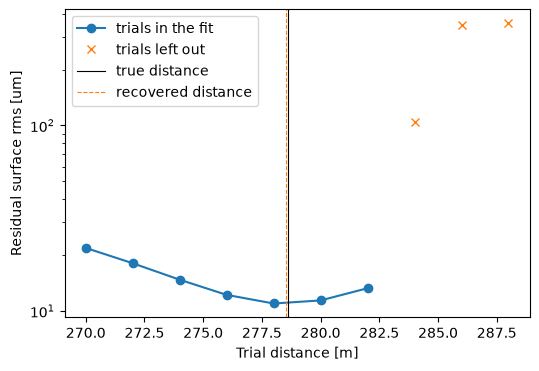

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
converged = np.array(rotating["converged"])
distances, residuals = np.array(rotating["distances"]), np.array(rotating["residuals"])
ax.plot(distances[converged], residuals[converged], "o-", label="trials in the fit")
ax.plot(distances[~converged], residuals[~converged], "x", label="trials left out")
ax.axvline(true_distance, color="k", lw=0.8, label="true distance")
ax.axvline(rotating["distance"], color="C1", ls="--", lw=0.8, label="recovered distance")
ax.set_yscale("log")
ax.set_xlabel("Trial distance [m]")
ax.set_ylabel("Residual surface rms [um]")
ax.legend()
plt.show()

## The geometry matters

ALMA antennas turn about their elevation axis while they map the transmitter, so the distance from the aperture centre to the transmitter changes during the map. In the model of Baars et al. (2007), which `holog`'s corrections follow, the transmitter stays at the same distance from the aperture centre. We simulate the same map with that fixed geometry, `geometry="fixed"`, and estimate the distance again.

In [6]:
simulate_alma_nf_holog(
    holog_name="sim_tf04_fixed.holog.zarr",
    distance=true_distance,
    geometry="fixed",
    surface_bumps=bumps,
    overwrite=True,
)
fixed = estimate_nf_distance(holog_name="sim_tf04_fixed.holog.zarr", distances=trials)

for name, result in (("rotating", rotating), ("fixed", fixed)):
    print(f"{name:9s} geometry: recovered {result['distance']:.2f} m, {result['distance'] - true_distance:+.2f} m from the true distance")

[-1.97857853 -0.08408876  0.08677917  8.40453774 -0.27168979  0.25541826
 -0.01025959  0.01442088]


[-1.92249072 -0.08408895  0.08680667  6.46886205 -0.27139022  0.25420894
 -0.01038625  0.01442215]


[-1.86723083 -0.08407272  0.08678985  4.56143387 -0.27163849  0.25447247
 -0.01041459  0.01442601]


[-1.81280203 -0.08405803  0.08677404  2.68179373 -0.27184     0.25470669
 -0.01044295  0.01442777]


[-1.75904164 -0.08403976  0.0867553   0.82863321 -0.2721642   0.25504181
 -0.01047198  0.01443048]


...

[-1.6540259  -0.08401063  0.08672559 -2.79777611 -0.2725786   0.25546737
 -0.01052512  0.01443433]


[-1.60714454e+00 -8.08426723e-02  8.35665132e-02 -4.54971753e+00
 -3.81418437e-01  3.63996599e-01 -1.05024939e-02 -3.67060392e-03]


[-2.51713178e+00  6.56506805e-02 -6.21625192e-02  3.37220417e+00
  7.60168944e+00 -7.73363278e+00 -2.60526167e-03  5.28459409e-01]


[ -0.66674276   0.96279122  -1.03921087   0.45448257 -15.33517966
  14.82275203   0.69761577   2.58919943]


rotating  geometry: recovered 278.52 m, -0.11 m from the true distance
fixed     geometry: recovered 280.75 m, +2.12 m from the true distance


## Summary

- For an antenna that turns about its elevation axis, as ALMA antennas do, the distance at which the phase fit leaves the smallest residual is within a few tenths of a meter of the true distance.
- With the fixed geometry the estimate is about 2 m too far, so it depends on how the antenna moved during the map.
- On real data, use the recovered distance through `holog`'s `nf_distance` parameter. `simulate_alma_nf_holog` can also use a measured map as its `template_holog_name`, to test the estimate with the real sampling.